In [1]:
import sys
sys.path.append("..")

from src.data_prep import build_dataset, FEATURES
from src.evaluation import evaluate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

train = build_dataset([2014, 2015, 2016])
val = build_dataset([2017])

X_cols = FEATURES + ["has_loss"]

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000),
)

model.fit(train[X_cols], train["above_median"])
proba = model.predict_proba(val[X_cols])[:, 1]

evaluate(val, proba, "Logistisk regression")

Accuracy                      0.572
ROC-AUC                       0.610
Topp 10 % (median avk.)      -9.901
Botten 10 % (median avk.)   -43.031
Alla (median avk.)          -16.319
Name: Logistisk regression, dtype: float64

## Gradient boosting

In [2]:
import sys
sys.path.append("..")

import pandas as pd
from src.data_prep import build_dataset, FEATURES
from src.evaluation import evaluate
from sklearn.ensemble import HistGradientBoostingClassifier

train = build_dataset([2014, 2015, 2016])
val = build_dataset([2017])

X_cols = FEATURES + ["has_loss"]

model = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=100,
    max_depth=3,
    min_samples_leaf=20,
    early_stopping=False,
    random_state=42,
)

model.fit(train[X_cols], train["above_median"])
proba = model.predict_proba(val[X_cols])[:, 1]

evaluate(val, proba, "Gradient boosting")

Accuracy                      0.583
ROC-AUC                       0.612
Topp 10 % (median avk.)      -9.723
Botten 10 % (median avk.)   -44.427
Alla (median avk.)          -16.319
Name: Gradient boosting, dtype: float64

In [3]:
results = []
for lr in [0.05, 0.1]:
    for n_trees in [100, 300]:
        m = HistGradientBoostingClassifier(
            learning_rate=lr, max_iter=n_trees, max_depth=3,
            min_samples_leaf=20, early_stopping=False, random_state=42,
        )
        m.fit(train[X_cols], train["above_median"])
        results.append(evaluate(val, m.predict_proba(val[X_cols])[:, 1],
                                f"lr={lr}, träd={n_trees}"))

pd.DataFrame(results)

,Accuracy,ROC-AUC,Topp 10 % (median avk.),Botten 10 % (median avk.),Alla (median avk.)
"lr=0.05, träd=100",0.583,0.612,-9.723,-44.427,-16.319
"lr=0.05, träd=300",0.574,0.605,-10.053,-39.592,-16.319
"lr=0.1, träd=100",0.576,0.608,-9.833,-42.898,-16.319
"lr=0.1, träd=300",0.563,0.594,-10.113,-36.559,-16.319


Free Cash Flow margin    0.0293
PE ratio                 0.0133
Market Cap               0.0111
PB ratio                 0.0078
EPS Growth               0.0061
debtEquityRatio          0.0057
Revenue Growth           0.0051
interestCoverage         0.0036
Gross Margin             0.0027
currentRatio             0.0009
ROE                      0.0008
Dividend Yield           0.0007
Net Profit Margin        0.0001
has_loss                 0.0000
priceToSalesRatio       -0.0073
dtype: float64

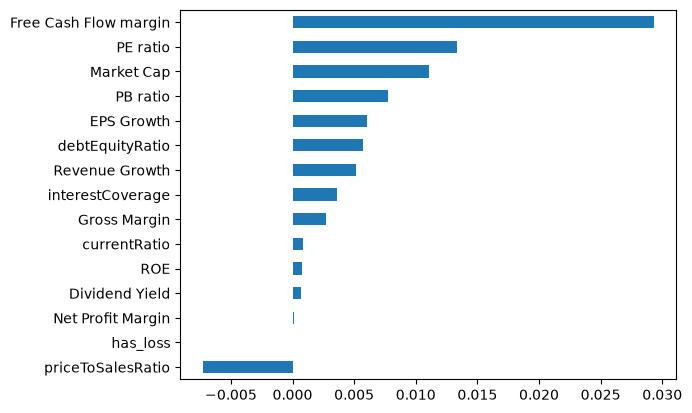

In [4]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(model, val[X_cols], val["above_median"],
                            scoring="roc_auc", n_repeats=5, random_state=42)
importance = pd.Series(pi.importances_mean, index=X_cols).sort_values()
importance.plot(kind="barh")
importance.sort_values(ascending=False).round(4)

In [5]:
from sklearn.metrics import confusion_matrix

y_pred = (proba >= 0.5).astype(int)
print(confusion_matrix(val["above_median"], y_pred))

val_res = val.assign(correct=(y_pred == val["above_median"]))
val_res.groupby("Sector")["correct"].mean().sort_values().round(3)

[[1194  870]
 [ 853 1210]]


Sector
Real Estate               0.494
Basic Materials           0.520
Consumer Cyclical         0.542
Consumer Defensive        0.549
Financial Services        0.559
Technology                0.591
Industrials               0.601
Healthcare                0.637
Energy                    0.645
Utilities                 0.650
Communication Services    0.654
Name: correct, dtype: float64

### Gradient boosting är bara marginellt bättre än logistisk regression. Skillnaden är så liten att den kan bero på slumpen. En mer avancerad modell behöver inte ge bättre urval. En trolig förklaring är att sambanden mellan nyckeltal och avkastning är svaga och ganska enkla.